# 31. Operator Monotone and Operator Convex Functions
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Testing the Loewner–Heinz inequality. For $4000$ random pairs $0\le A\le B$ of $3\times3$ matrices, the fraction for which $A^p\le B^p$ still holds, as a function of $p$. It is exactly $1$ for $0\le p\le1$ and drops abruptly after: the power $p=1$ is a sharp threshold, unlike for numbers, where every positive power is monotone. (Here $B-A$ has rank one, which makes failure generic as soon as $p>1$.)

(0.0, 1.05)

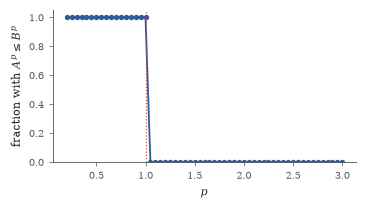

In [2]:
rng = np.random.default_rng(0); pairs = []
for _ in range(4000):
    Xa = rng.normal(size=(3, 3)); Aa = Xa @ Xa.T; Pd = rng.normal(size=(3, 1)); Bb = Aa + Pd @ Pd.T * rng.uniform(0.05, 1)
    pairs.append((np.linalg.eigh(Aa), np.linalg.eigh(Bb)))
mpow = lambda eh, p: (eh[1] * np.maximum(eh[0], 0) ** p) @ eh[1].T
ps = np.linspace(0.2, 3, 57); frac = [np.mean([np.linalg.eigvalsh(mpow(eb, p) - mpow(ea, p))[0] > -1e-9 for ea, eb in pairs]) for p in ps]
fig, ax = plt.subplots(figsize=(W * 0.7, 1.8))
ax.plot(ps, frac, "o-", color=BLUE, ms=2.5); ax.axvline(1, color=RED, ls=":", lw=0.8); ax.set_xlabel("$p$"); ax.set_ylabel(r"fraction with $A^p\leq B^p$"); ax.set_ylim(0, 1.05)

Loewner matrices $L_f=(f^{[1]}(\lambda_i,\lambda_j))$ at $12$ points in $(0,4]$: the smallest eigenvalue, normalized by the largest, for $f(t)=t^p/p$ as a function of $p$ (blue), and for $\log t$ (gold star, at $p=0$, where $(t^p-1)/p\to\log t$). It is nonnegative exactly for $-1\le p\le1$: for $0<p\le1$ this is the Loewner–Heinz range, and for $-1\le p<0$ it says that $t^p$ is operator monotone *decreasing*, generalizing $A\le B\Rightarrow B^{-1}\le A^{-1}$.

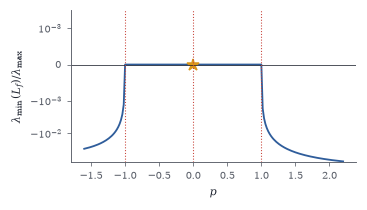

In [3]:
pts = np.linspace(0.3, 4, 12)
def loew(f, fp, x):
    L = (f(x)[:, None] - f(x)[None, :]) / (x[:, None] - x[None, :] + np.eye(len(x))); L[np.diag_indices(len(x))] = fp(x); return L
ps2 = np.linspace(-1.6, 2.2, 191); mins = []
for p in ps2:
    if abs(p) < 1e-9: mins.append(np.nan); continue
    ev = np.linalg.eigvalsh(loew(lambda t: t**p / p, lambda t: t**(p - 1), pts)); mins.append(ev[0] / np.abs(ev).max())
evl = np.linalg.eigvalsh(loew(np.log, lambda t: 1 / t, pts))
fig, ax = plt.subplots(figsize=(W * 0.7, 1.8))
ax.plot(ps2, mins, color=BLUE); ax.plot(0, evl[0] / evl.max(), "*", color=GOLD, ms=8); ax.axhline(0, color=INK, lw=0.5)
for b in (-1, 0, 1): ax.axvline(b, color=RED, ls=":", lw=0.7)
ax.set_xlabel("$p$"); ax.set_ylabel(r"$\lambda_{\min}(L_f)/\lambda_{\max}$"); ax.set_yscale("symlog", linthresh=1e-3)

Operator convexity of $t^p$: for $3000$ random pairs of positive definite $3\times3$ matrices and $t=\frac12$, the smallest eigenvalue of $\frac12A^p+\frac12B^p-\big(\frac{A+B}2\big)^p$, normalized by $\lVert A^p\rVert+\lVert B^p\rVert$ (minimum over all pairs, blue). It is nonnegative exactly on $[-1,0]\cup[1,2]$ (operator convex range, shaded) and the reverse, operator concavity, holds on $[0,1]$.

Text(0, 0.5, 'worst normalized gap')

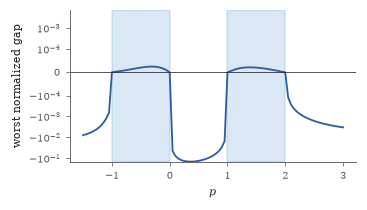

In [4]:
rng = np.random.default_rng(2); prs = []
for _ in range(3000):
    Xa, Xb = rng.normal(size=(3, 3)), rng.normal(size=(3, 3)); prs.append((Xa @ Xa.T + 0.05 * np.eye(3), Xb @ Xb.T + 0.05 * np.eye(3)))
def mp(M, p): lam, U = np.linalg.eigh(M); return (U * lam**p) @ U.T
ps3 = np.linspace(-1.5, 3, 91); worst = []
for p in ps3:
    worst.append(min(np.linalg.eigvalsh(0.5 * mp(A_, p) + 0.5 * mp(B_, p) - mp(0.5 * (A_ + B_), p))[0] / (np.linalg.norm(mp(A_, p), 2) + np.linalg.norm(mp(B_, p), 2)) for A_, B_ in prs[:600]))
fig, ax = plt.subplots(figsize=(W * 0.7, 1.8))
ax.plot(ps3, worst, color=BLUE); ax.axhline(0, color=INK, lw=0.5); ax.axvspan(-1, 0, color=SKY, alpha=0.25); ax.axvspan(1, 2, color=SKY, alpha=0.25)
ax.set_yscale("symlog", linthresh=1e-4); ax.set_xlabel("$p$"); ax.set_ylabel("worst normalized gap")

Interpolating between two positive definite $2\times2$ matrices, drawn as ellipses $\{x: x^{\mathsf T}M^{-1}x\leq1\}$. Top: the linear path $(1-t)A+tB$ swells in the middle (its determinant exceeds the geometric interpolation). Bottom: the geometric path $A\#_tB$, the geodesic of the natural Riemannian metric on positive definite matrices, keeps $\det(A\#_tB)=\det A^{1-t}\det B^{t}$ and passes through the geometric mean at $t=\frac12$ (red).

Text(0.5, 1.0, 'geometric interpolation $A\\#_tB$')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


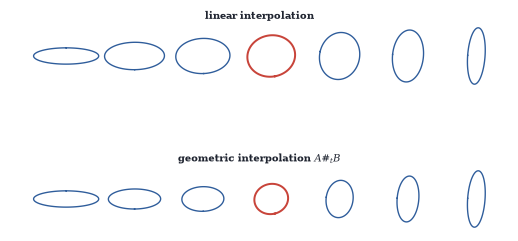

In [5]:
def ell(ax, M, x0, col, lw=1.0):
    th = np.linspace(0, 2 * np.pi, 120); lam, U = np.linalg.eigh(M); pts_ = U @ (np.sqrt(lam)[:, None] * np.vstack([np.cos(th), np.sin(th)])); ax.plot(pts_[0] + x0, pts_[1], color=col, lw=lw)
Ae = np.array([[4.0, 0], [0, 0.25]]); Be = np.array([[0.3, 0.2], [0.2, 3.0]]); ts5 = np.linspace(0, 1, 7)
def geo(A_, B_, t):
    la, Ua = np.linalg.eigh(A_); Ah = (Ua * np.sqrt(la)) @ Ua.T; Aih = (Ua / np.sqrt(la)) @ Ua.T; return Ah @ mp(Aih @ B_ @ Aih, t) @ Ah
fig, axs = plt.subplots(2, 1, figsize=(W, 2.6))
for row, path in enumerate([lambda t: (1 - t) * Ae + t * Be, lambda t: geo(Ae, Be, t)]):
    for k, t in enumerate(ts5): ell(axs[row], path(t), 4.2 * k, RED if k == 3 else BLUE, 1.3 if k == 3 else 0.9)
    axs[row].set_aspect("equal"); axs[row].axis("off")
axs[0].set_title("linear interpolation", fontsize=6.5); axs[1].set_title("geometric interpolation $A\\#_tB$", fontsize=6.5)

In [6]:
rng = np.random.default_rng(7)
for trial in range(10000):
    Xa, Xb = rng.normal(size=(2, 2)), rng.normal(size=(2, 2)); A2, B2 = Xa @ Xa.T + 0.01 * np.eye(2), Xb @ Xb.T + 0.01 * np.eye(2)
    gap = 0.5 * (np.linalg.matrix_power(A2, 3) + np.linalg.matrix_power(B2, 3)) - np.linalg.matrix_power(0.5 * (A2 + B2), 3)
    if np.linalg.eigvalsh(gap)[0] < -1e-6: break
print("found after", trial + 1, "trials; smallest eigenvalue of the gap:", round(np.linalg.eigvalsh(gap)[0], 5)); print(np.round(A2, 3)); print(np.round(B2, 3))

found after 1 trials; smallest eigenvalue of the gap: -0.03133
[[ 0.099 -0.266]
 [-0.266  0.878]]
[[ 1.2   -1.356]
 [-1.356  1.81 ]]


In [7]:
rng = np.random.default_rng(4); Xa, Xb = rng.normal(size=(2, 2)), rng.normal(size=(2, 2)); Ag, Bg = Xa @ Xa.T + 0.1 * np.eye(2), Xb @ Xb.T + 0.1 * np.eye(2)
Xg = geo(Ag, Bg, 0.5); Yg = geo(Bg, Ag, 0.5)
print("X A^-1 X = B:", np.allclose(Xg @ np.linalg.inv(Ag) @ Xg, Bg), "  det X = sqrt(det A det B):", np.isclose(np.linalg.det(Xg), np.sqrt(np.linalg.det(Ag) * np.linalg.det(Bg))), "  A#B = B#A:", np.allclose(Xg, Yg))
al, be = np.linalg.det(Ag), np.linalg.det(Bg); Sg = np.sqrt(be) * Ag + np.sqrt(al) * Bg
print("closed 2x2 formula agrees:", np.allclose(Xg, (al * be) ** 0.25 * Sg / np.sqrt(np.linalg.det(Sg))))

X A^-1 X = B: True   det X = sqrt(det A det B): True   A#B = B#A: True
closed 2x2 formula agrees: True


In [8]:
rng = np.random.default_rng(8); ok = True; bad = 0
for _ in range(500):
    Xa, Xb = rng.normal(size=(4, 4)), rng.normal(size=(4, 4)); A4, B4 = Xa @ Xa.T + 0.1 * np.eye(4), Xb @ Xb.T + 0.1 * np.eye(4)
    G4 = geo(A4, B4, 0.5); H4 = 2 * np.linalg.inv(np.linalg.inv(A4) + np.linalg.inv(B4)); M4 = (A4 + B4) / 2
    ok &= np.linalg.eigvalsh(G4 - H4)[0] > -1e-9 and np.linalg.eigvalsh(M4 - G4)[0] > -1e-9
    Ah = mp(A4, 0.5); Z4 = mp(Ah @ B4 @ Ah, 0.5); bad += np.linalg.eigvalsh(M4 - Z4)[0] < -1e-9
print("harmonic <= geometric <= arithmetic in all 500 trials:", ok, "   (A^1/2 B A^1/2)^1/2 <= (A+B)/2 failed in", bad, "trials")

harmonic <= geometric <= arithmetic in all 500 trials: True    (A^1/2 B A^1/2)^1/2 <= (A+B)/2 failed in 360 trials


In [9]:
def psd_sqrt(M):
    lam, U = np.linalg.eigh(M); return (U * np.sqrt(np.clip(lam, 0, None))) @ U.T
rng = np.random.default_rng(9); worst = 0
for _ in range(2000):
    Xa = rng.normal(size=(5, 2)); A5 = Xa @ Xa.T; E5 = rng.normal(size=(5, 5)) * 1e-4; B5 = A5 + E5 @ E5.T
    worst = max(worst, np.linalg.norm(psd_sqrt(B5) - psd_sqrt(A5), 2) / np.sqrt(np.linalg.norm(B5 - A5, 2)))
print("max ||sqrt(B) - sqrt(A)|| / ||B - A||^(1/2) over 2000 trials:", round(worst, 4))

max ||sqrt(B) - sqrt(A)|| / ||B - A||^(1/2) over 2000 trials: 0.9999
